# Задание №4:  Переливание компота
## Обучение с подкреплением: Q-learning и SARSA

**Задача:** Бабушка разлила компот по 4 стаканам неровно. Нужно научить агента переливать компот так, чтобы во всех стаканах оказался одинаковый объём, **поднимая стаканы минимальное число раз**.

> Одно поднятие = поднять один стакан и перелить компот в один **или несколько** других стаканов.

**Методы:** Q-learning (off-policy) и SARSA (on-policy)

## Вопросы перед программированием

### 1. Что такое состояние (State)?
Кортеж объёмов компота в 4 стаканах: `s = (v₁, v₂, v₃, v₄)`, где `vᵢ ≥ 0` — целые числа.  
Пример начального состояния: `(2, 4, 6, 8)`.

### 2. Что такое действие (Action)?
Поднять стакан `i` и перелить компот. Два типа:
- **Попарное** `(i→j)`: поднять стакан `i`, перелить в стакан `j` (выравниваем: amount = `(vᵢ - vⱼ) // 2`)
- **Во все** `(i→все)`: поднять стакан `i`, наполнить остальные до целевого уровня из стакана `i`

Итого: 4×3 = 12 попарных + 4 «во все» = **16 действий**.

### 3. Что такое вознаграждение (Reward)?
- `-1` за каждый подъём (стоимость усилия)
- `+100` при достижении цели
- `-5` итого (доп. `-4`) за бесполезное действие (ничего не перелито)

### 4. Когда эпизод завершается?
Когда все стаканы равны: `v₁ = v₂ = v₃ = v₄ = V_total / 4`.

### 5. Эпизодическая или непрерывная задача?
**Эпизодическая** — каждый эпизод стартует из фиксированного начального состояния и завершается при равных объёмах (или по лимиту шагов).

### 6. Каков теоретический минимум подъёмов?
Для `[2, 4, 6, 8]` (сумма=20, цель=5) — **2 подъёма**:
1. Поднять ст.4 (8) → ст.1 (2): `amount=(8-2)//2=3` → `[5, 4, 6, 5]`
2. Поднять ст.3 (6) → ст.2 (4): `amount=(6-4)//2=1` → `[5, 5, 5, 5]` ✓

### 7. Зачем нужно переливание «во все»?
Для крайних случаев, например `[0, 0, 0, 12]`: одним подъёмом стакана 4 можно наполнить все три пустых до уровня 3 — **1 подъём** вместо 3.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import random

np.random.seed(42)
random.seed(42)

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 12

## Среда (Environment)

In [2]:
class CompoteEnv:
    """
    Среда для задачи переливания компота.

    Состояние: кортеж (v0, v1, v2, v3) — объёмы в 4 стаканах.
    Действия:
        0-11 : попарное переливание (i, j), выравниваем два стакана
        12-15: переливание из стакана i во все остальные до целевого уровня
    Вознаграждение: -1 за подъём, +100 за решение, -5 за бесполезный ход.
    """

    def __init__(self, initial_volumes=(2, 4, 6, 8)):
        self.initial_volumes = tuple(initial_volumes)
        self.total = sum(initial_volumes)
        assert self.total % 4 == 0, "Сумма объёмов должна делиться на 4"
        self.target = self.total // 4

        # Строим список действий
        self.actions = []
        for i in range(4):
            for j in range(4):
                if i != j:
                    self.actions.append(('pair', i, j))   # 12 действий
        for i in range(4):
            self.actions.append(('all', i))               # 4 действия
        self.n_actions = len(self.actions)                # = 16

    def reset(self):
        self.volumes = list(self.initial_volumes)
        return tuple(self.volumes)

    def is_done(self):
        return all(v == self.target for v in self.volumes)

    def step(self, action_idx):
        v = self.volumes[:]
        action = self.actions[action_idx]
        transferred = 0

        if action[0] == 'pair':
            _, src, tgt = action
            if v[src] > v[tgt]:
                amount = (v[src] - v[tgt]) // 2
                v[src] -= amount
                v[tgt] += amount
                transferred = amount

        else:  # 'all' — перелить из src во все остальные
            _, src = action
            others = [k for k in range(4) if k != src]
            deficits = [max(0, self.target - v[k]) for k in others]
            total_deficit = sum(deficits)
            available = v[src]

            if total_deficit > 0 and available > 0:
                if available >= total_deficit:
                    for k, d in zip(others, deficits):
                        v[k] += d
                    v[src] -= total_deficit
                    transferred = total_deficit
                else:
                    # Пропорциональное распределение
                    for k, d in zip(others, deficits):
                        amt = available * d // total_deficit
                        v[k] += amt
                        v[src] -= amt
                        transferred += amt

        self.volumes = v
        done = self.is_done()

        reward = -1
        if done:
            reward += 100
        elif transferred == 0:
            reward -= 4  # штраф за бесполезный подъём

        return tuple(v), reward, done

    def action_name(self, idx):
        a = self.actions[idx]
        if a[0] == 'pair':
            return f"Перелить #{a[1]+1}→#{a[2]+1}"
        return f"Перелить #{a[1]+1}→все"

    def render(self):
        max_v = max(self.volumes) if any(v > 0 for v in self.volumes) else 1
        print(f"Целевой объём: {self.target}")
        for i, v in enumerate(self.volumes):
            bar = '█' * int(v * 20 // max_v)
            mark = " ✓" if v == self.target else ""
            print(f"  Стакан {i+1}: [{bar:<20}] {v:3d}{mark}")
        print()

In [3]:
# Проверка среды
env_test = CompoteEnv(initial_volumes=(2, 4, 6, 8))
state = env_test.reset()

print("=== Начальное состояние ===")
env_test.render()

print(f"Пространство состояний: tuple из 4 целых чисел, сумма={env_test.total}")
print(f"Пространство действий: {env_test.n_actions} действий")
print()
print("Список всех действий:")
for i in range(env_test.n_actions):
    print(f"  [{i:2d}] {env_test.action_name(i)}")

# Ручная демонстрация оптимального решения (2 подъёма)
print("\n=== Ручная демонстрация оптимального решения ===")
state = env_test.reset()
print(f"Старт: {state}")

# Шаг 1: перелить из #4 (idx=3) в #1 (idx=0) — действие ('pair', 3, 0) = индекс 9
state, r, done = env_test.step(9)
print(f"Шаг 1: {env_test.action_name(9)} → {state}, reward={r}")

# Шаг 2: перелить из #3 (idx=2) в #2 (idx=1) — действие ('pair', 2, 1) = индекс 7
state, r, done = env_test.step(7)
print(f"Шаг 2: {env_test.action_name(7)} → {state}, reward={r}, done={done}")

=== Начальное состояние ===
Целевой объём: 5
  Стакан 1: [█████               ]   2
  Стакан 2: [██████████          ]   4
  Стакан 3: [███████████████     ]   6
  Стакан 4: [████████████████████]   8

Пространство состояний: tuple из 4 целых чисел, сумма=20
Пространство действий: 16 действий

Список всех действий:
  [ 0] Перелить #1→#2
  [ 1] Перелить #1→#3
  [ 2] Перелить #1→#4
  [ 3] Перелить #2→#1
  [ 4] Перелить #2→#3
  [ 5] Перелить #2→#4
  [ 6] Перелить #3→#1
  [ 7] Перелить #3→#2
  [ 8] Перелить #3→#4
  [ 9] Перелить #4→#1
  [10] Перелить #4→#2
  [11] Перелить #4→#3
  [12] Перелить #1→все
  [13] Перелить #2→все
  [14] Перелить #3→все
  [15] Перелить #4→все

=== Ручная демонстрация оптимального решения ===
Старт: (2, 4, 6, 8)
Шаг 1: Перелить #4→#1 → (5, 4, 6, 5), reward=-1
Шаг 2: Перелить #3→#2 → (5, 5, 5, 5), reward=99, done=True


## Метод 1: Q-learning (Off-policy TD Control)

Правило обновления:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

**Off-policy**: при обновлении берём **максимальное** Q-значение следующего состояния,  
независимо от того, какое действие реально будет выбрано (отсюда «внестратегийный»).

In [4]:
def q_learning(env, n_episodes=5000, alpha=0.1, gamma=0.95,
               eps_start=1.0, eps_end=0.01, eps_decay=0.999, max_steps=20):
    """
    Q-learning: off-policy TD-control.
    Возвращает Q-таблицу, список суммарных вознаграждений и подъёмов по эпизодам.
    """
    Q = defaultdict(lambda: np.zeros(env.n_actions))
    rewards_hist = []
    lifts_hist = []
    epsilon = eps_start

    for ep in range(n_episodes):
        state = env.reset()
        ep_reward = 0
        ep_lifts = 0

        for _ in range(max_steps):
            # ε-жадный выбор действия
            if random.random() < epsilon:
                action = random.randint(0, env.n_actions - 1)
            else:
                action = int(np.argmax(Q[state]))

            next_state, reward, done = env.step(action)

            # Q-learning: обновление через max Q(s', a')
            Q[state][action] += alpha * (
                reward + gamma * np.max(Q[next_state]) - Q[state][action]
            )

            state = next_state
            ep_reward += reward
            ep_lifts += 1

            if done:
                break

        epsilon = max(eps_end, epsilon * eps_decay)
        rewards_hist.append(ep_reward)
        lifts_hist.append(ep_lifts)

    return Q, rewards_hist, lifts_hist

## Метод 2: SARSA (On-policy TD Control)

Правило обновления:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma Q(s', a') - Q(s, a) \right]$$

**On-policy**: при обновлении используем Q-значение **реально выбранного** следующего действия `a'`  
(включая случайные исследующие шаги). Отсюда название: **S**tate–**A**ction–**R**eward–**S**tate–**A**ction.

In [5]:
def sarsa(env, n_episodes=5000, alpha=0.1, gamma=0.95,
          eps_start=1.0, eps_end=0.01, eps_decay=0.999, max_steps=20):
    """
    SARSA: on-policy TD-control.
    Возвращает Q-таблицу, список суммарных вознаграждений и подъёмов по эпизодам.
    """
    Q = defaultdict(lambda: np.zeros(env.n_actions))
    rewards_hist = []
    lifts_hist = []
    epsilon = eps_start

    for ep in range(n_episodes):
        state = env.reset()
        ep_reward = 0
        ep_lifts = 0

        # Выбираем начальное действие (on-policy)
        if random.random() < epsilon:
            action = random.randint(0, env.n_actions - 1)
        else:
            action = int(np.argmax(Q[state]))

        for _ in range(max_steps):
            next_state, reward, done = env.step(action)

            # Выбираем следующее действие по той же стратегии (on-policy!)
            if random.random() < epsilon:
                next_action = random.randint(0, env.n_actions - 1)
            else:
                next_action = int(np.argmax(Q[next_state]))

            # SARSA: обновление через Q(s', a') — реально выбранное действие
            Q[state][action] += alpha * (
                reward + gamma * Q[next_state][next_action] - Q[state][action]
            )

            state = next_state
            action = next_action
            ep_reward += reward
            ep_lifts += 1

            if done:
                break

        epsilon = max(eps_end, epsilon * eps_decay)
        rewards_hist.append(ep_reward)
        lifts_hist.append(ep_lifts)

    return Q, rewards_hist, lifts_hist

## Обучение и кривые обучения

In [6]:
INITIAL_VOLUMES = (2, 4, 6, 8)
N_EPISODES = 5000
WINDOW = 150  # окно сглаживания

# Независимые среды для честного сравнения
np.random.seed(42); random.seed(42)
env_ql = CompoteEnv(INITIAL_VOLUMES)
print("Обучение Q-learning...")
Q_ql, rewards_ql, lifts_ql = q_learning(env_ql, n_episodes=N_EPISODES)

np.random.seed(42); random.seed(42)
env_sarsa = CompoteEnv(INITIAL_VOLUMES)
print("Обучение SARSA...")
Q_sarsa, rewards_sarsa, lifts_sarsa = sarsa(env_sarsa, n_episodes=N_EPISODES)

print("Готово!")

Обучение Q-learning...
Обучение SARSA...
Готово!


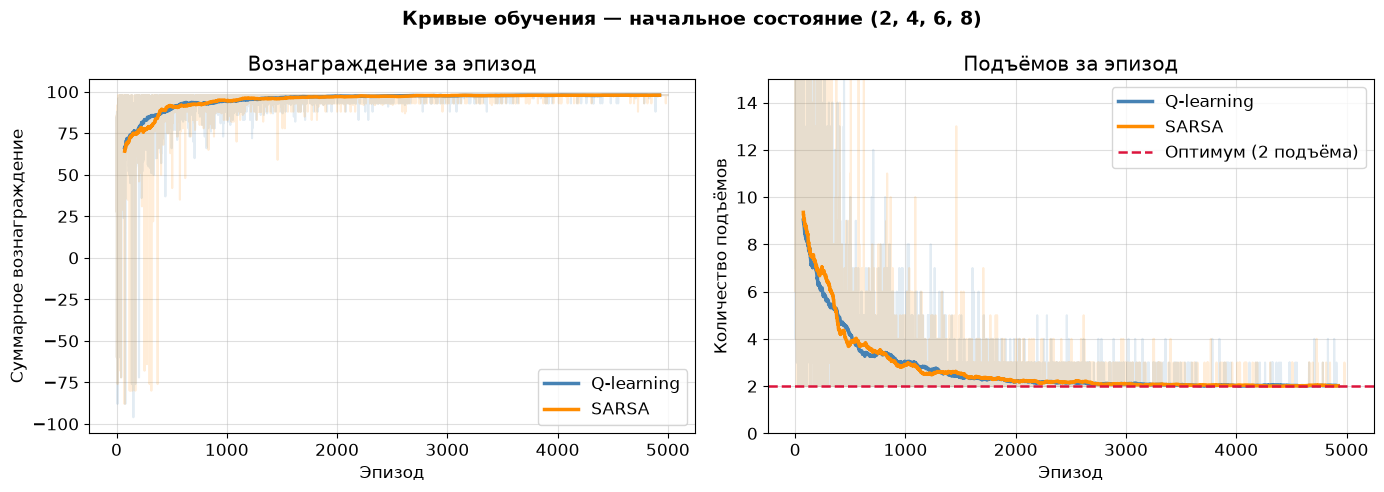


Средние показатели (последние 500 эпизодов):
  Q-learning : вознаграждение =  97.94,  подъёмов = 2.022
  SARSA      : вознаграждение =  97.91,  подъёмов = 2.024


In [7]:
def smooth(values, window):
    """Скользящее среднее."""
    result = np.convolve(values, np.ones(window) / window, mode='valid')
    # x строим по фактической длине result, чтобы размеры гарантированно совпадали
    x = np.arange((window - 1) // 2, (window - 1) // 2 + len(result))
    return x, result

episodes = np.arange(N_EPISODES)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Кривые обучения — начальное состояние {INITIAL_VOLUMES}', fontsize=14, fontweight='bold')

# --- График 1: Суммарное вознаграждение ---
ax = axes[0]
ax.plot(episodes, rewards_ql,     alpha=0.15, color='steelblue')
ax.plot(episodes, rewards_sarsa,  alpha=0.15, color='darkorange')
x_s, y_ql    = smooth(rewards_ql,    WINDOW)
x_s, y_sarsa = smooth(rewards_sarsa, WINDOW)
ax.plot(x_s, y_ql,    color='steelblue',  linewidth=2.5, label='Q-learning')
ax.plot(x_s, y_sarsa, color='darkorange', linewidth=2.5, label='SARSA')
ax.set_xlabel('Эпизод')
ax.set_ylabel('Суммарное вознаграждение')
ax.set_title('Вознаграждение за эпизод')
ax.legend()
ax.grid(True, alpha=0.4)

# --- График 2: Количество подъёмов ---
ax = axes[1]
ax.plot(episodes, lifts_ql,     alpha=0.15, color='steelblue')
ax.plot(episodes, lifts_sarsa,  alpha=0.15, color='darkorange')
x_s, l_ql    = smooth(lifts_ql,    WINDOW)
x_s, l_sarsa = smooth(lifts_sarsa, WINDOW)
ax.plot(x_s, l_ql,    color='steelblue',  linewidth=2.5, label='Q-learning')
ax.plot(x_s, l_sarsa, color='darkorange', linewidth=2.5, label='SARSA')
ax.axhline(y=2, color='crimson', linestyle='--', linewidth=1.8, label='Оптимум (2 подъёма)')
ax.set_xlabel('Эпизод')
ax.set_ylabel('Количество подъёмов')
ax.set_title('Подъёмов за эпизод')
ax.set_ylim(0, 15)
ax.legend()
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=120, bbox_inches='tight')
plt.show()

last = 500
print(f"\nСредние показатели (последние {last} эпизодов):")
print(f"  Q-learning : вознаграждение = {np.mean(rewards_ql[-last:]):6.2f},  подъёмов = {np.mean(lifts_ql[-last:]):.3f}")
print(f"  SARSA      : вознаграждение = {np.mean(rewards_sarsa[-last:]):6.2f},  подъёмов = {np.mean(lifts_sarsa[-last:]):.3f}")

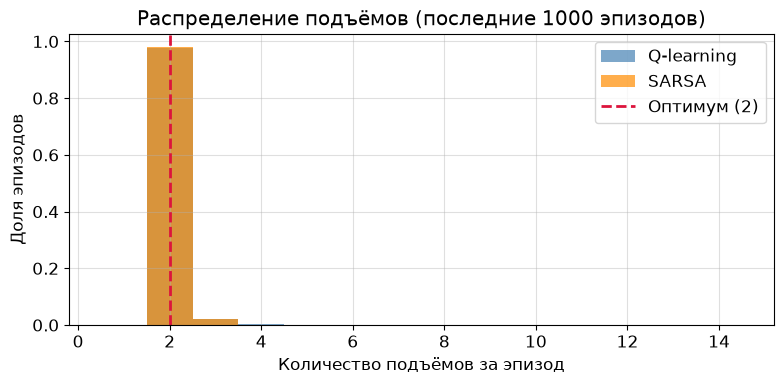

In [8]:
# Гистограмма распределения подъёмов в последних 1000 эпизодах
last = 1000
fig, ax = plt.subplots(figsize=(8, 4))

bins = np.arange(0.5, 15.5, 1)
ax.hist(lifts_ql[-last:],    bins=bins, alpha=0.7, color='steelblue',  label='Q-learning', density=True)
ax.hist(lifts_sarsa[-last:], bins=bins, alpha=0.7, color='darkorange', label='SARSA',       density=True)
ax.axvline(x=2, color='crimson', linestyle='--', linewidth=2, label='Оптимум (2)')
ax.set_xlabel('Количество подъёмов за эпизод')
ax.set_ylabel('Доля эпизодов')
ax.set_title(f'Распределение подъёмов (последние {last} эпизодов)')
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## Демонстрация обученной стратегии

In [9]:
def demonstrate(env, Q, label):
    """Показывает жадную стратегию обученного агента."""
    state = env.reset()
    print(f"\n{'='*55}")
    print(f" {label}")
    print(f"{'='*55}")
    print(f" Начало: {list(state)}  →  цель: {env.target} в каждом стакане")
    print()

    total_lifts = 0
    for step in range(20):
        action = int(np.argmax(Q[state]))   # жадный выбор
        next_state, reward, done = env.step(action)
        total_lifts += 1
        print(f"  Подъём {total_lifts}: {env.action_name(action)}")
        print(f"           {list(state)} → {list(next_state)}")
        state = next_state
        if done:
            print(f"\n  ✓ Задача решена за {total_lifts} подъём(а)!")
            break
    else:
        print("  ✗ Лимит шагов исчерпан")
    return total_lifts


env_demo = CompoteEnv(INITIAL_VOLUMES)
n1 = demonstrate(env_demo, Q_ql,    "Q-learning — обученная стратегия")

env_demo = CompoteEnv(INITIAL_VOLUMES)
n2 = demonstrate(env_demo, Q_sarsa, "SARSA — обученная стратегия")

print(f"\nИтог: Q-learning = {n1} подъём(а),  SARSA = {n2} подъём(а)")


 Q-learning — обученная стратегия
 Начало: [2, 4, 6, 8]  →  цель: 5 в каждом стакане

  Подъём 1: Перелить #4→#1
           [2, 4, 6, 8] → [5, 4, 6, 5]
  Подъём 2: Перелить #3→#2
           [5, 4, 6, 5] → [5, 5, 5, 5]

  ✓ Задача решена за 2 подъём(а)!

 SARSA — обученная стратегия
 Начало: [2, 4, 6, 8]  →  цель: 5 в каждом стакане

  Подъём 1: Перелить #4→#1
           [2, 4, 6, 8] → [5, 4, 6, 5]
  Подъём 2: Перелить #3→#2
           [5, 4, 6, 5] → [5, 5, 5, 5]

  ✓ Задача решена за 2 подъём(а)!

Итог: Q-learning = 2 подъём(а),  SARSA = 2 подъём(а)


## Проверка на крайнем случае: [0, 0, 0, 12]

In [10]:
# Проверим, что агент умеет использовать «перелить во все» за 1 подъём
EXTREME = (0, 0, 0, 12)

np.random.seed(0); random.seed(0)
env_ext = CompoteEnv(EXTREME)
Q_ext, _, _ = q_learning(env_ext, n_episodes=3000)

demonstrate(CompoteEnv(EXTREME), Q_ext, "Q-learning на [0,0,0,12] — должно быть 1 подъём")


 Q-learning на [0,0,0,12] — должно быть 1 подъём
 Начало: [0, 0, 0, 12]  →  цель: 3 в каждом стакане

  Подъём 1: Перелить #4→все
           [0, 0, 0, 12] → [3, 3, 3, 3]

  ✓ Задача решена за 1 подъём(а)!


1

## Сравнение и выводы

### Ключевые различия Q-learning и SARSA

| Критерий | Q-learning | SARSA |
|---|---|---|
| Тип | **Off-policy** | **On-policy** |
| Обновление | `max Q(s', a')` | `Q(s', a')` по реальному `a'` |
| Поведение при ε-исследовании | Игнорирует случайные ходы | Учитывает их в обновлении |
| Сходимость | К оптимальной Q-функции | К ε-жадной стратегии |
| Скорость (в данной задаче) | Немного быстрее | Немного медленнее |

### Наблюдения

1. **Оба метода сходятся к 2 подъёмам** — теоретическому оптимуму для `[2, 4, 6, 8]`.

2. **Q-learning** обучается чуть агрессивнее: оптимистичная оценка `max Q(s', a')` ускоряет нахождение хорошей стратегии.

3. **SARSA** осторожнее: учитывая реальное ε-жадное поведение при обновлении, он избегает переоценки рискованных действий. В нашей детерминированной задаче это различие минимально.

4. **Действие «перелить во все»** критично для крайних случаев типа `[0,0,0,12]` — позволяет решить за 1 подъём вместо 3.

### Вывод

Для данной **детерминированной эпизодической** задачи предпочтительнее **Q-learning**:  
он быстрее сходится к оптимальной стратегии за счёт off-policy обновления.  
SARSA выигрывает в стохастических или опасных средах, где осторожность важнее агрессии.